In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ibrahimelsayed182/superstore/SampleSuperstore.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv(r"/kaggle/input/datasets/ibrahimelsayed182/superstore/SampleSuperstore.csv")

In [4]:
df.head()

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


In [5]:
df.shape

(9994, 13)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Ship Mode     9994 non-null   object 
 1   Segment       9994 non-null   object 
 2   Country       9994 non-null   object 
 3   City          9994 non-null   object 
 4   State         9994 non-null   object 
 5   Postal Code   9994 non-null   int64  
 6   Region        9994 non-null   object 
 7   Category      9994 non-null   object 
 8   Sub-Category  9994 non-null   object 
 9   Sales         9994 non-null   float64
 10  Quantity      9994 non-null   int64  
 11  Discount      9994 non-null   float64
 12  Profit        9994 non-null   float64
dtypes: float64(3), int64(2), object(8)
memory usage: 1015.1+ KB


In [7]:
df.describe()

,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55190.379428,229.858001,3.789574,0.156203,28.656896
std,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,90008.000000,209.940000,5.000000,0.200000,29.364000
max,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [8]:
df["Sales"].mean()

np.float64(229.85800083049833)

In [9]:
df["Profit"].max()

8399.976

In [10]:
df["Sales"].min()


0.444

In [11]:
df.isna().sum()

Ship Mode       0
Segment         0
Country         0
City            0
State           0
Postal Code     0
Region          0
Category        0
Sub-Category    0
Sales           0
Quantity        0
Discount        0
Profit          0
dtype: int64

In [12]:
missing = df.isnull().sum()

missing[missing > 0]

Series([], dtype: int64)

In [13]:
df.duplicated().sum()

np.int64(17)

In [14]:
df[df.duplicated()]

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
950,Standard Class,Home Office,United States,Philadelphia,Pennsylvania,19120,East,Office Supplies,Paper,15.552,3,0.2,5.4432
3406,Standard Class,Home Office,United States,Columbus,Ohio,43229,East,Furniture,Chairs,281.372,2,0.3,-12.0588
3670,Standard Class,Consumer,United States,Salem,Oregon,97301,West,Office Supplies,Paper,10.368,2,0.2,3.6288
4117,Standard Class,Consumer,United States,Los Angeles,California,90036,West,Office Supplies,Paper,19.440,3,0.0,9.3312
4553,Standard Class,Consumer,United States,San Francisco,California,94122,West,Office Supplies,Paper,12.840,3,0.0,5.7780
5905,Same Day,Home Office,United States,San Francisco,California,94122,West,Office Supplies,Labels,41.400,4,0.0,19.8720
6146,Standard Class,Corporate,United States,San Francisco,California,94122,West,Office Supplies,Art,11.760,4,0.0,3.1752
6334,Standard Class,Consumer,United States,New York City,New York,10011,East,Office Supplies,Paper,49.120,4,0.0,23.0864
6357,Standard Class,Corporate,United States,Seattle,Washington,98103,West,Office Supplies,Paper,25.920,4,0.0,12.4416
7608,Standard Class,Consumer,United States,San Francisco,California,94122,West,Office Supplies,Paper,25.920,4,0.0,12.4416


In [15]:
df = df.drop_duplicates()

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df.shape

(9977, 13)

In [18]:
df.dtypes

Ship Mode        object
Segment          object
Country          object
City             object
State            object
Postal Code       int64
Region           object
Category         object
Sub-Category     object
Sales           float64
Quantity          int64
Discount        float64
Profit          float64
dtype: object

In [19]:
df[df["Sales"] < 0]

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit


In [20]:
df[df["Quantity"] <= 0]

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit


In [21]:
df[df["Discount"] < 0]

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit


In [22]:
df[df["Discount"] > 1]

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit


In [23]:
df[df["Profit"] < 0]

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
14,Standard Class,Home Office,United States,Fort Worth,Texas,76106,Central,Office Supplies,Appliances,68.8100,5,0.80,-123.8580
15,Standard Class,Home Office,United States,Fort Worth,Texas,76106,Central,Office Supplies,Binders,2.5440,3,0.80,-3.8160
23,Second Class,Consumer,United States,Philadelphia,Pennsylvania,19140,East,Furniture,Chairs,71.3720,2,0.30,-1.0196
27,Standard Class,Consumer,United States,Philadelphia,Pennsylvania,19140,East,Furniture,Bookcases,3083.4300,7,0.50,-1665.0522
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9920,Standard Class,Corporate,United States,Bryan,Texas,77803,Central,Office Supplies,Binders,22.3860,7,0.80,-35.8176
9921,Standard Class,Home Office,United States,Akron,Ohio,44312,East,Office Supplies,Binders,5.7420,3,0.70,-4.5936
9931,Standard Class,Consumer,United States,San Bernardino,California,92404,West,Furniture,Bookcases,683.3320,4,0.15,-40.1960
9937,Second Class,Corporate,United States,Los Angeles,California,90049,West,Furniture,Tables,71.0880,2,0.20,-1.7772


In [24]:
print(df["Category"].unique())

['Furniture' 'Office Supplies' 'Technology']


In [25]:
print(df["Region"].unique())

['South' 'West' 'Central' 'East']


In [26]:
print(df["Segment"].unique())

['Consumer' 'Corporate' 'Home Office']


In [27]:
print(df["Sub-Category"].unique())

['Bookcases' 'Chairs' 'Labels' 'Tables' 'Storage' 'Furnishings' 'Art'
 'Phones' 'Binders' 'Appliances' 'Paper' 'Accessories' 'Envelopes'
 'Fasteners' 'Supplies' 'Machines' 'Copiers']


In [28]:
print("Dataset Shape:", df.shape)

print("Missing Values:")
print(df.isnull().sum().sum())

print("Duplicate Records:")
print(df.duplicated().sum())

print("Data Types:")
print(df.dtypes)

Dataset Shape: (9977, 13)
Missing Values:
0
Duplicate Records:
0
Data Types:
Ship Mode        object
Segment          object
Country          object
City             object
State            object
Postal Code       int64
Region           object
Category         object
Sub-Category     object
Sales           float64
Quantity          int64
Discount        float64
Profit          float64
dtype: object


Data Analysis on Superstore_dataset

In [29]:
total_sales = df["Sales"].sum()
print("Total Sales:", total_sales)

Total Sales: 2296195.5903


In [30]:
total_profit = df["Profit"].sum()
print("Total Profit:", total_profit)

Total Profit: 286241.4226


In [31]:
total_quantity = df["Quantity"].sum()
print("Total Quantity:", total_quantity)

Total Quantity: 37820


In [32]:
average_sales = df["Sales"].mean()
print("Average Sales:", average_sales)

Average Sales: 230.14890150345792


In [33]:
average_profit = df["Profit"].mean()
print("Average Profit:", average_profit)

Average Profit: 28.69012955798336


In [34]:
profit_margin = (total_profit / total_sales) * 100

print("Profit Margin:", profit_margin)

Profit Margin: 12.465898976950927


In [35]:
category_sales = df.groupby("Category")["Sales"].sum()

print(category_sales)

Category
Furniture          741306.3133
Office Supplies    718735.2440
Technology         836154.0330
Name: Sales, dtype: float64


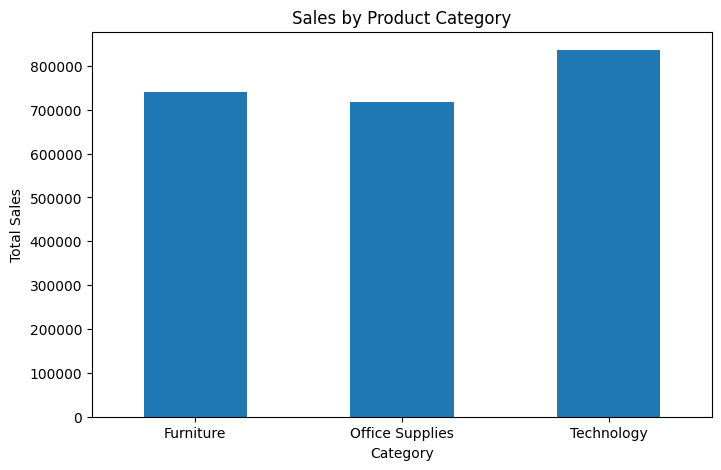

In [36]:
category_sales.plot(kind="bar", figsize=(8,5))

plt.title("Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)

plt.show()

1. Technology generates the highest sales
2. Office Supplies category generates the lowest sales

In [37]:
region_sales = df.groupby("Region")["Sales"].sum()

print(region_sales)

Region
Central    500782.8528
East       678435.1960
South      391721.9050
West       725255.6365
Name: Sales, dtype: float64


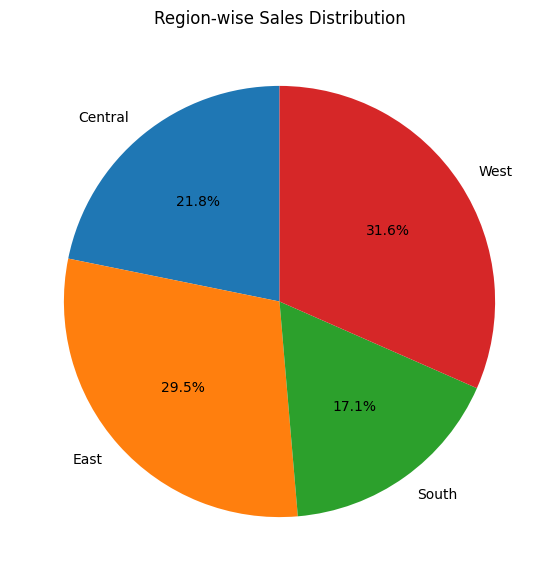

In [38]:
plt.figure(figsize=(7,7))

plt.pie(
    region_sales,
    labels=region_sales.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Region-wise Sales Distribution")

plt.show()

1. West Region has the highest sales share at 31.6%, followed by the East Region at 29.5%.

2. South Region has the lowest sales share at 17.1%, while Central contributes 21.8% of total sales.

In [39]:
top_products = (
    df.groupby("Sub-Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Sub-Category
Phones         330007.0540
Chairs         327777.7610
Storage        223843.6080
Tables         206965.5320
Binders        203409.1690
Machines       189238.6310
Accessories    167380.3180
Copiers        149528.0300
Bookcases      114879.9963
Appliances     107532.1610
Name: Sales, dtype: float64


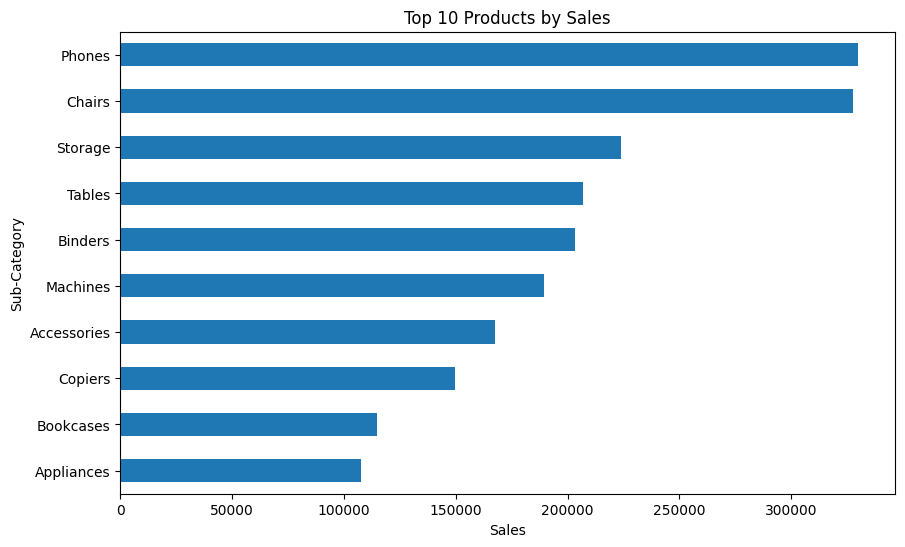

In [40]:
top_products.sort_values().plot(
    kind="barh",
    figsize=(10,6)
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Sales")

plt.show()

1. Phones generate the highest sales (approximately 330,000), followed closely by Chairs (approximately 328,000), making them the top-performing products.

2. Appliances have the lowest sales (approximately 108,000), while Bookcases and Copiers also show comparatively lower sales.

In [41]:
df.head()

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


In [42]:
df["Ship Mode"].unique()

array(['Second Class', 'Standard Class', 'First Class', 'Same Day'],
      dtype=object)

In [43]:
df["State"].nunique()

49

In [44]:
top_City = (
    df.groupby("City")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_City)

City
New York City    256319.0410
Los Angeles      175831.9010
Seattle          119460.2820
San Francisco    112577.1720
Philadelphia     109061.4610
Houston           64441.2564
Chicago           48535.9770
San Diego         47521.0290
Jacksonville      44713.1830
Springfield       43054.3420
Name: Sales, dtype: float64


In [45]:
total_Ship_Mode = (
    df.groupby("Ship Mode")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(total_Ship_Mode)

Ship Mode
Standard Class    1.357316e+06
Second Class      4.591770e+05
First Class       3.513805e+05
Same Day          1.283217e+05
Name: Sales, dtype: float64


In [46]:
category_profit = df.groupby("Category")["Profit"].sum()

print(category_profit)

Category
Furniture           18421.8137
Office Supplies    122364.6608
Technology         145454.9481
Name: Profit, dtype: float64


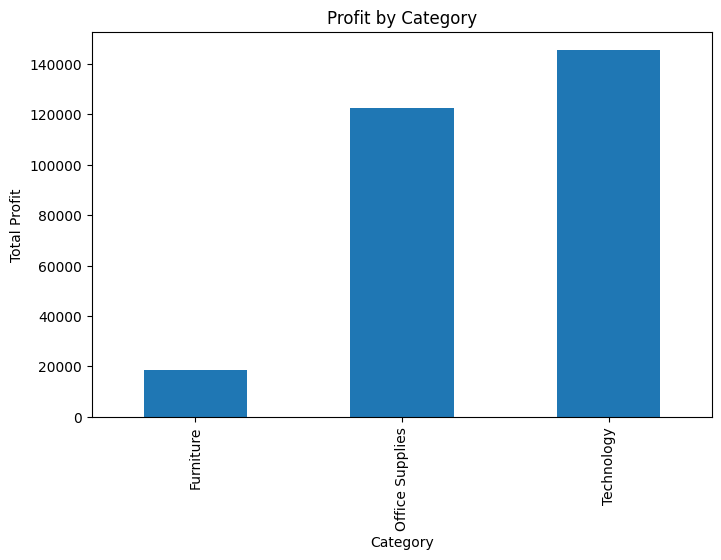

In [47]:
category_profit.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")

plt.show()

1. Technology generates the highest profit (approximately 146,000), making it the most profitable category.

2. Furniture generates the lowest profit (approximately 19,000), while Office Supplies contributes around 123,000 in total profit.

In [48]:
correlation = df[
    ["Sales", "Profit", "Quantity", "Discount"]
].corr()

print(correlation)

             Sales    Profit  Quantity  Discount
Sales     1.000000  0.479067  0.200722 -0.028311
Profit    0.479067  1.000000  0.066211 -0.219662
Quantity  0.200722  0.066211  1.000000  0.008678
Discount -0.028311 -0.219662  0.008678  1.000000


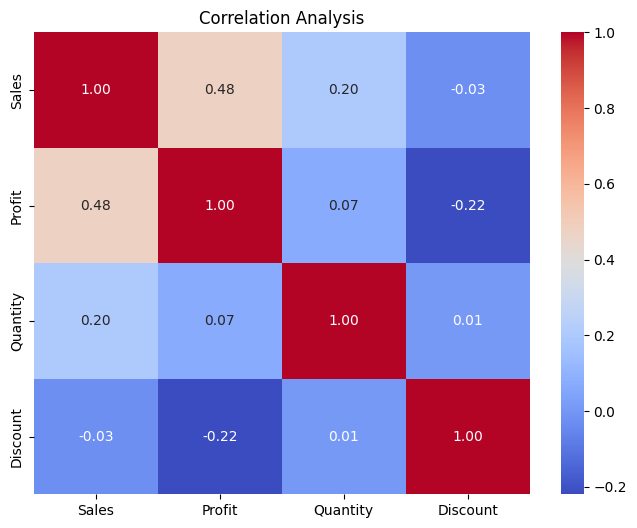

In [49]:
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Analysis")

plt.show()

1. Sales and Profit show a moderate positive correlation of 0.48, indicating that higher sales are generally associated with higher profits.

2. Profit and Discount have a negative correlation of -0.22, suggesting that higher discounts may be associated with lower profits.

3. Quantity has a weak relationship with both sales (0.20) and profit (0.07), indicating a limited correlation.

Overall Insight: Sales have the strongest positive relationship with profit, while discounts show a negative relationship with profit.

In [50]:
print("===== SALES ANALYSIS REPORT =====")

print("Total Sales:", round(df["Sales"].sum(), 2))

print("Total Profit:", round(df["Profit"].sum(), 2))

print("Total Quantity:", df["Quantity"].sum())

print("Average Sales:", round(df["Sales"].mean(), 2))

print("Highest Sales Category:",
      df.groupby("Category")["Sales"].sum().idxmax())

print("Highest Profit Category:",
      df.groupby("Category")["Profit"].sum().idxmax())

print("Best Sales Region:",
      df.groupby("Region")["Sales"].sum().idxmax())

===== SALES ANALYSIS REPORT =====
Total Sales: 2296195.59
Total Profit: 286241.42
Total Quantity: 37820
Average Sales: 230.15
Highest Sales Category: Technology
Highest Profit Category: Technology
Best Sales Region: West


In [51]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_Sub_Category = df["Sub-Category"].nunique()
total_quantity = df["Quantity"].sum()

average_order_value = total_sales / total_Sub_Category 

profit_margin = (total_profit / total_sales) * 100

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("total_Sub-Category :", total_Sub_Category )
print("Total Quantity:", total_quantity)
print("Average Order Value:", round(average_order_value, 2))
print("Profit Margin:", round(profit_margin, 2), "%")

Total Sales: 2296195.59
Total Profit: 286241.42
total_Sub-Category : 17
Total Quantity: 37820
Average Order Value: 135070.33
Profit Margin: 12.47 %


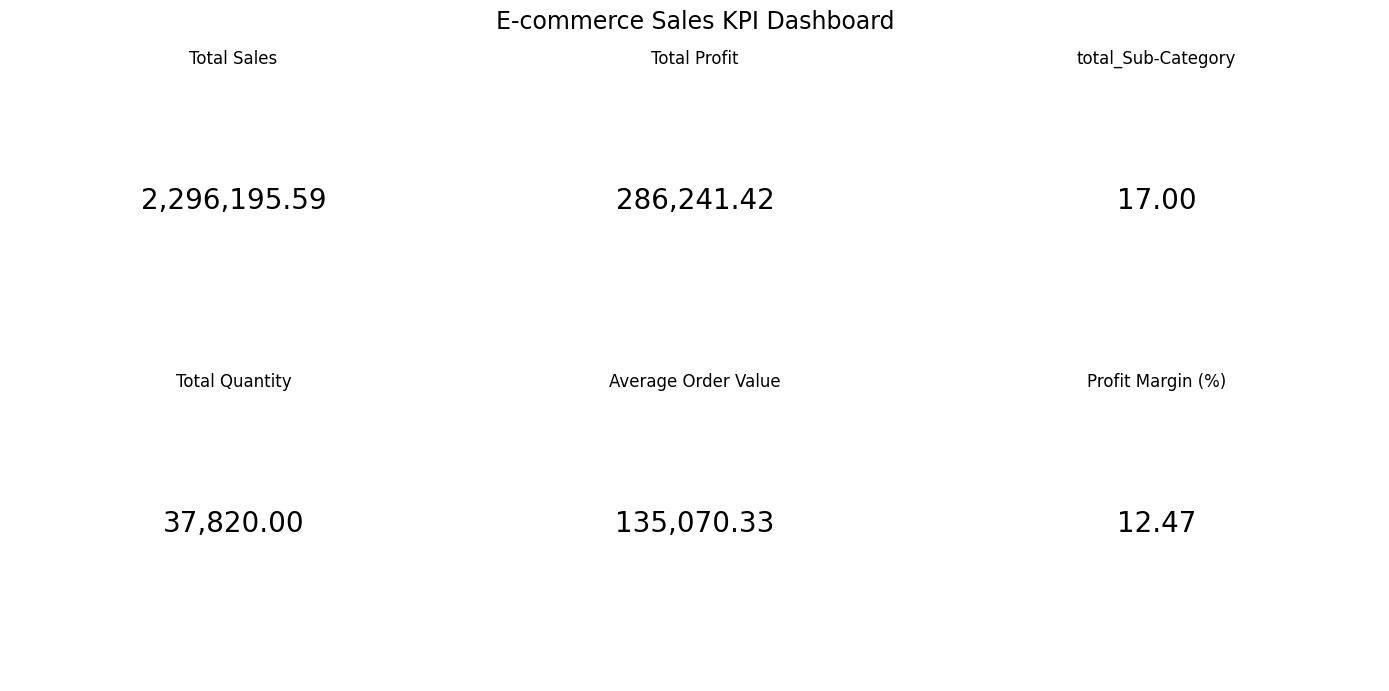

In [52]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

kpis = [
    ("Total Sales", total_sales),
    ("Total Profit", total_profit),
    ("total_Sub-Category", total_Sub_Category),
    ("Total Quantity", total_quantity),
    ("Average Order Value", average_order_value),
    ("Profit Margin (%)", profit_margin)
]

for ax, (title, value) in zip(axes.flat, kpis):
    ax.text(0.5, 0.55, f"{value:,.2f}",
            ha="center", va="center", fontsize=20)
    ax.set_title(title)
    ax.axis("off")

plt.suptitle("E-commerce Sales KPI Dashboard", fontsize=17)
plt.tight_layout()
plt.show()

In [53]:
category_data = df.groupby("Category")[["Sales", "Profit"]].sum()

print(category_data)

                       Sales       Profit
Category                                 
Furniture        741306.3133   18421.8137
Office Supplies  718735.2440  122364.6608
Technology       836154.0330  145454.9481


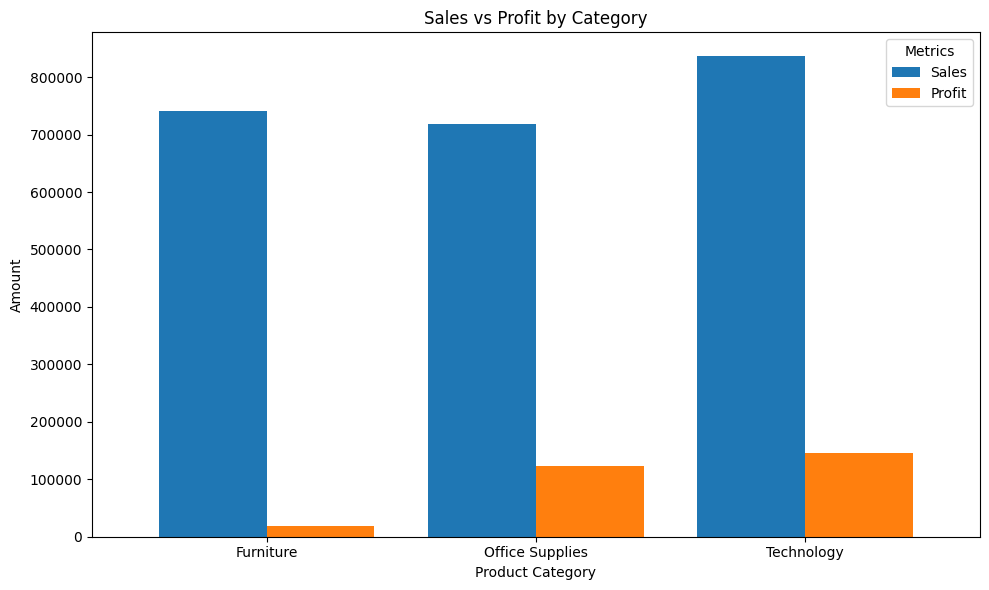

In [54]:
category_data.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

plt.title("Sales vs Profit by Category")
plt.xlabel("Product Category")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

1. Technology has the highest sales (approximately 836,000) and profit (approximately 146,000), making it the best-performing category.

2. Furniture generates high sales (approximately 742,000) but the lowest profit (approximately 19,000), indicating lower profitability compared to other categories.

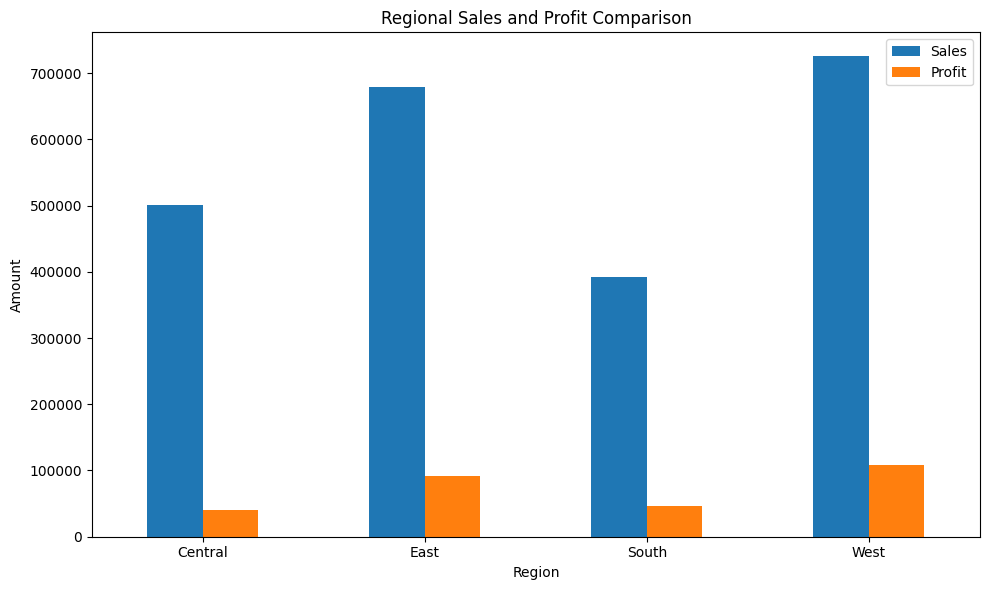

In [55]:
region_data = df.groupby("Region")[["Sales", "Profit"]].sum()

region_data.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Regional Sales and Profit Comparison")
plt.xlabel("Region")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

1. West Region has the highest sales (approximately 725,000) and profit (approximately 108,000), making it the best-performing region.

2. South Region has the lowest sales (approximately 393,000), while Central and East show moderate performance. East generates the second-highest profit (approximately 92,000).